# 05 · Forecasting new budget plans

This notebook covers the operational use case from the brief: *"short-term assessment of the business"*. Marketing provides a **budget plan** for the coming weeks, and the model returns a **daily sales forecast** with uncertainty.

**How it works:**

- Meridian only predicts inside the time window it is fitted on.
- The plan's days are therefore appended to the history as **hold-out rows** (their sales are unknown), and the model is refit. This takes about 2–3 minutes on a laptop CPU.
- The rows' sales placeholder is the training mean, so Meridian's KPI scaling (which also uses hold-out rows) is unchanged and no real future sales are used.

**Input: a CSV plan** (template: `data/input/budget_plan_template.csv`)

| column | content |
|---|---|
| `date` | consecutive days, starting the day after the last history day |
| `sea, catalog, display, affiliate, display_network, social_media, psm` | planned daily cost in € (catalog: full cost on the send-out day, as in the history) |

**Command line:**

```bash
uv run tchibo-forecast --plan data/input/budget_plan_2025-01.csv --out outputs/forecast_2025-01.csv
```

**Two kinds of interval:**

- **90 % prediction interval:** where an *actual* day's sales are expected to land. This is the one to use for planning.
- **90 % credible interval:** uncertainty about the *expected* sales level only (much narrower).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tchibo_mmm import data, evaluate
from tchibo_mmm import forecast as F
from tchibo_mmm.plotting import CHANNEL_COLORS, INK_2, MUTED, TOTAL_COLOR, save, thousands, use_style

warnings.filterwarnings("ignore")
use_style()
pd.set_option("display.float_format", "{:,.0f}".format)

raw = data.load_raw()
wide = data.build_wide_table(raw)
COLORS = {data.slug(c): CHANNEL_COLORS[c] for c in data.PAID_CHANNELS}
NAMES = {data.slug(c): c for c in data.PAID_CHANNELS}
PLAN_PATH = data.PROJECT_ROOT / "data" / "input" / "budget_plan_2025-01.csv"
OUT = data.PROJECT_ROOT / "outputs"


def plot_forecast(ax, daily, color=CHANNEL_COLORS["SEA"], label="Forecast"):
    ax.fill_between(daily.index, daily.prediction_lo, daily.prediction_hi, color=color, alpha=0.15, lw=0,
                    label="90 % prediction interval")
    ax.plot(daily.index, daily.forecast, color=color, lw=1.8, label=label)

## 1. Does the pipeline forecast well? A leak-free back-test

- **Training data:** only history up to **2024-09-30**.
- **Plan:** the **actual Q4-2024 spend**, as if it had been the plan.
- **Not used:** no Q4 sales at all, not even in the KPI scaling.

MAE/mean 8.5% | RMSE 115,205 | R² 0.888 | bias +68,890/day | days inside 90 % prediction interval: 80%


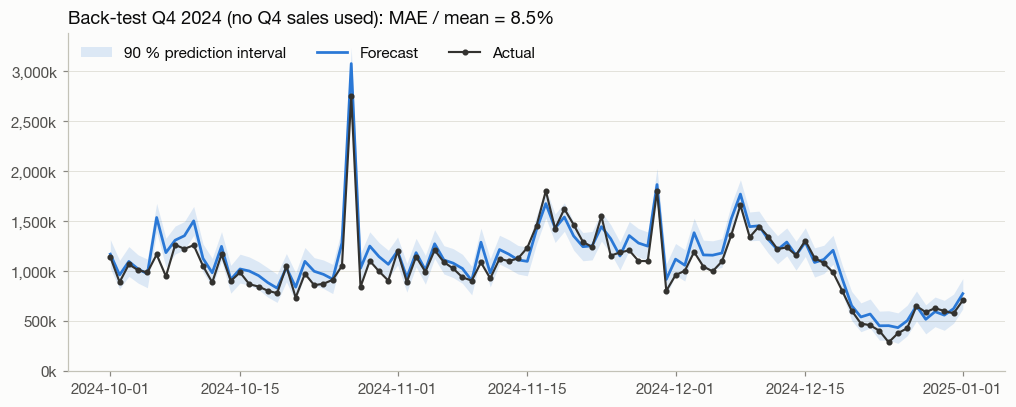

In [2]:
hist_q3 = wide.loc[:"2024-09-30"]
q4 = wide.loc["2024-10-01":]
plan_q4 = pd.DataFrame({c: q4[f"cost_{c}"] for c in F.PLAN_COLUMNS})
bt = F.forecast(plan_q4, history=hist_q3)
d = bt.daily.join(q4["total_sales"].rename("actual"))
bt_metrics = evaluate.metrics(d.actual, d.forecast)
coverage = ((d.actual >= d.prediction_lo) & (d.actual <= d.prediction_hi)).mean()
print(f"MAE/mean {bt_metrics['MAE/mean']:.1%} | RMSE {bt_metrics['RMSE']:,.0f} | R² {bt_metrics['R2']:.3f} | "
      f"bias {bt_metrics['bias']:+,.0f}/day | days inside 90 % prediction interval: {coverage:.0%}")

fig, ax = plt.subplots(figsize=(11, 4))
plot_forecast(ax, d)
ax.plot(d.index, d.actual, color=TOTAL_COLOR, lw=1.4, marker="o", ms=3, label="Actual")
thousands(ax, unit="k")
ax.set_ylim(0)
ax.set_title(f"Back-test Q4 2024 (no Q4 sales used): MAE / mean = {bt_metrics['MAE/mean']:.1%}")
ax.legend(loc="upper left", ncols=3)
save(fig, "05_backtest_q4");

**Reading the back-test:**

- **Accuracy matches notebook 03** (≈ 8.5 %), so the small KPI-scaling effect there was negligible.
- **Interval coverage is below the nominal 90 %.** This is because of the level offset seen before: Q4 2024 came in about 6–7 % below the trend.
- **In operation, refitting weekly** re-anchors the level and keeps this offset small.

## 2. The new input: example budget plan, 2 Jan – 12 Feb 2025

Marketing's real plan replaces this file. For the demonstration, `forecast.example_plan` builds a plan from history:

- **Digital channels:** each day gets the average spend of the same weekday in the same window of 2024, scaled by the channel's year-on-year spend growth.
- **Catalog:** two send-outs on Thursday 9 Jan and Thursday 30 Jan, at the 2024 average cost per send-out.

In [3]:
plan = F.load_plan(PLAN_PATH)
print(f"{len(plan)} days, {plan.index[0].date()} .. {plan.index[-1].date()} | total planned spend "
      f"{plan.to_numpy().sum():,.0f} €")
weekly_plan = plan.resample("W-SUN").sum().rename(columns=NAMES)
weekly_plan

42 days, 2025-01-02 .. 2025-02-12 | total planned spend 8,008,549 €


,SEA,Catalog,Display,Affiliate,Display Network,Social Media,PSM
date,,,,,,,
2025-01-05,"247,952",0,"150,326","46,655","24,629","27,456","15,158"
2025-01-12,"428,256","1,299,842","269,740","73,167","44,003","59,310","27,001"
2025-01-19,"428,256",0,"269,740","73,167","44,003","59,310","27,001"
2025-01-26,"428,256",0,"269,740","73,167","44,003","59,310","27,001"
2025-02-02,"428,256","1,299,842","269,740","73,167","44,003","59,310","27,001"
2025-02-09,"428,256",0,"269,740","73,167","44,003","59,310","27,001"
2025-02-16,"180,304",0,"119,414","26,512","19,374","31,854","11,843"


## 3. Forecast for the plan

forecast: 42,585,010 € sales over 42 days (Ø 1,013,929 €/day) for 8,008,549 € spend -> outputs/forecast_2025-01.csv


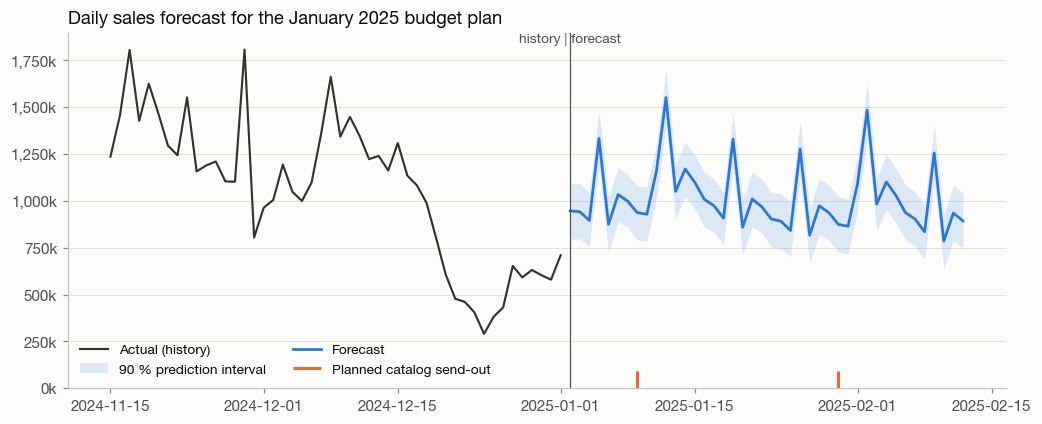

In [4]:
fc = F.forecast(plan)
daily = fc.daily
daily.round(0).to_csv(OUT / "forecast_2025-01.csv")
print(f"forecast: {daily.forecast.sum():,.0f} € sales over {len(daily)} days "
      f"(Ø {daily.forecast.mean():,.0f} €/day) for {daily.planned_spend.sum():,.0f} € spend -> outputs/forecast_2025-01.csv")

recent = wide.loc["2024-11-15":, "total_sales"]
send = plan.index[plan["catalog"] > 0]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(recent.index, recent, color=TOTAL_COLOR, lw=1.4, label="Actual (history)")
plot_forecast(ax, daily)
ax.vlines(send, 0, recent.max() * 0.05, color=CHANNEL_COLORS["Catalog"], lw=2, label="Planned catalog send-out")
ax.axvline(daily.index[0], color=INK_2, lw=0.8)
ax.annotate("history | forecast", (daily.index[0], recent.max() * 1.02), ha="center", fontsize=9, color=INK_2)
thousands(ax, unit="k")
ax.set_ylim(0)
ax.set_title("Daily sales forecast for the January 2025 budget plan")
ax.legend(loc="lower left", ncols=2, fontsize=9)
save(fig, "05_forecast_2025_01");

In [5]:
weekly = daily[["forecast", "prediction_lo", "prediction_hi", "planned_spend"]].resample("W-SUN").sum()
weekly["days"] = daily.resample("W-SUN").size()
weekly.columns = ["forecast sales", "low (sum of daily 5 %)", "high (sum of daily 95 %)", "planned spend", "days"]
weekly

,forecast sales,low (sum of daily 5 %),high (sum of daily 95 %),planned spend,days
date,,,,,
2025-01-05,"4,116,814","3,537,917","4,706,035","512,176",4
2025-01-12,"7,481,083","6,466,346","8,487,166","2,201,319",7
2025-01-19,"7,538,517","6,529,223","8,539,230","901,478",7
2025-01-26,"6,750,110","5,733,177","7,769,584","901,478",7
2025-02-02,"7,042,088","6,011,809","8,059,984","2,201,319",7
2025-02-09,"7,043,609","6,026,825","8,062,166","901,478",7
2025-02-16,"2,612,788","2,172,748","3,051,463","389,301",3


The weekly *low/high* columns add up the daily interval bounds, so they are deliberately conservative (wider than a true weekly interval).

## 4. Budget scenarios on the same forecast window

Alternative plans are evaluated with the **fitted model**, so no refit is needed and each scenario takes seconds.

- Only media channels are changed.
- Affiliate stays as planned, because it enters as a control.

In [6]:
scenarios = {"plan as submitted": plan.copy()}
alt = plan.copy(); alt.loc["2025-01-30", "catalog"] = 0.0
scenarios["skip the 30 Jan catalog"] = alt
alt = plan.copy(); shift = 0.2 * alt["display"]; alt["display"] -= shift; alt["sea"] += shift
scenarios["move 20 % of Display to SEA"] = alt
alt = plan.copy(); alt[["sea", "display", "display_network", "social_media", "psm"]] *= 1.10
scenarios["+10 % on all digital channels"] = alt

rows = {}
for name, p in scenarios.items():
    s = F.scenario(fc, p)
    rows[name] = {"sales": s.forecast.sum(), "spend": p.to_numpy().sum()}
scen = pd.DataFrame(rows).T
base = scen.loc["plan as submitted"]
scen["Δ sales"] = scen.sales - base.sales
scen["Δ spend"] = scen.spend - base.spend
scen["Δ sales / Δ spend"] = (scen["Δ sales"] / scen["Δ spend"]).where(scen["Δ spend"].abs() > 1)
scen.style.format({"sales": "{:,.0f}", "spend": "{:,.0f}", "Δ sales": "{:+,.0f}", "Δ spend": "{:+,.0f}",
                   "Δ sales / Δ spend": "{:.2f}"}, na_rep="–")

,sales,spend,Δ sales,Δ spend,Δ sales / Δ spend
plan as submitted,"42,585,010","8,008,549",+0,+0,–
skip the 30 Jan catalog,"41,342,750","6,708,708","-1,242,260","-1,299,842",0.96
move 20 % of Display to SEA,"43,859,195","8,008,549","+1,274,185",+0,–
+10 % on all digital channels,"43,764,583","8,505,536","+1,179,573","+496,987",2.37


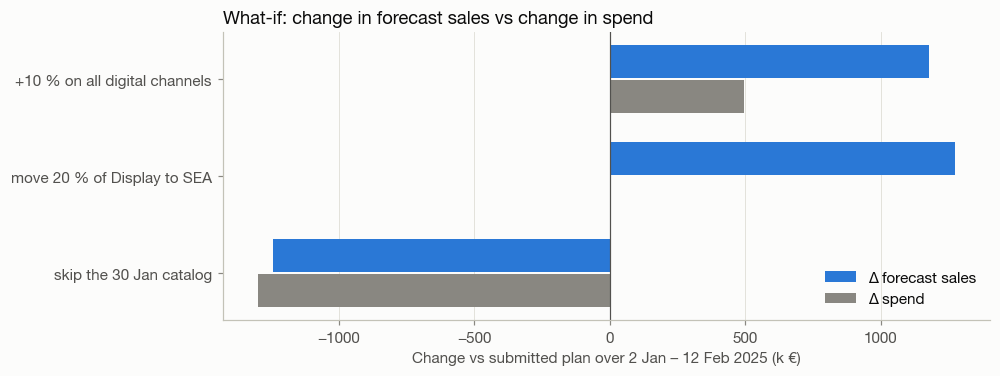

In [7]:
deltas = scen.drop(index="plan as submitted")
fig, ax = plt.subplots(figsize=(9, 3.4))
pos = np.arange(len(deltas))
ax.barh(pos + 0.18, deltas["Δ sales"] / 1e3, height=0.34, color=CHANNEL_COLORS["SEA"], label="Δ forecast sales")
ax.barh(pos - 0.18, deltas["Δ spend"] / 1e3, height=0.34, color=MUTED, label="Δ spend")
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_yticks(pos, deltas.index)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Change vs submitted plan over 2 Jan – 12 Feb 2025 (k €)")
ax.set_title("What-if: change in forecast sales vs change in spend")
ax.legend(loc="lower right")
save(fig, "05_scenarios");

**Reading the scenarios:**

- **Skipping a catalog** saves its cost but loses roughly the same amount of sales, consistent with a catalog ROI of about 1.
- **Moving Display budget to SEA** gains sales at zero extra cost. This is driven by SEA's high, upward-biased ROI (notebook 03), so it should be tested before acting on it.
- **+10 % on digital** shows the marginal return of extra spend.

**Using it with new data:**

1. Marketing fills `data/input/budget_plan_template.csv` with the planned daily costs.
2. Run `uv run tchibo-forecast --plan <file> --out <file>` (about 2–3 minutes).
3. When new actual sales arrive, append them to the history (the source workbook), so the next forecast refits on the latest level.